# Autenticação biométrica por padrão de digitação
**Kessia Macedo · EBAC × Semantix**

Notebook final da entrega local. O experimento completo está em `src/analysis.py`. As saídas aqui consultam artefatos reais, incluídos no projeto. Não há resultados simulados.

## Coleta de dados


### Problema e objetivo de negócio

Conhecer a senha não demonstra, por si só, que quem a digitou é o dono da conta. Este projeto investiga se o ritmo da digitação acrescenta informação para distinguir um participante dos demais. A decisão estudada é aceitar ou rejeitar uma tentativa em uma conta cadastrada. O custo de aceitar um impostor é diferente do custo de bloquear um usuário legítimo; por isso esses erros são apresentados separadamente.

O aprendizado de máquina é pertinente porque combina várias medidas de tempo e aprende diferenças entre pessoas. Uma regra baseada apenas na duração total perderia padrões individuais. O estudo é uma prova de conceito acadêmica e não um sistema de autenticação pronto para uso.

### Fonte, acesso e integridade

Usamos o [benchmark público da CMU](https://www.cs.cmu.edu/~keystroke/), de Killourhy e Maxion (2009), com participantes identificados por códigos. São 51 pessoas, 400 registros por pessoa, oito sessões e 50 repetições por sessão. A senha experimental comum é `.tie5Roanl`, seguida de Enter. O arquivo contém 20.400 linhas e 34 colunas. Não coletamos senhas reais nem novos dados de pessoas.

O [CSV oficial](https://www.cs.cmu.edu/~keystroke/DSL-StrongPasswordData.csv) foi conferido em 24/11/2026. Seu MD5 é `470235f96568f28f9ea0da62234ec857`. A cópia original da autora tinha os mesmos valores tabulares, embora os bytes fossem diferentes. A entrega inclui o arquivo oficial, o verificador de integridade e a referência da fonte. Identificadores codificados não garantem anonimato absoluto.

### Dicionário e qualidade

`subject` identifica o participante; `sessionIndex`, a sessão; `rep`, a repetição. São metadados, excluídos das entradas dos modelos. As 31 entradas são 11 tempos H (tecla pressionada), 10 DD (entre pressionamentos) e 10 UD (entre liberação e próximo pressionamento), em segundos. UD pode ser negativo; existe a relação DD = H + UD.

A conferência local encontrou **zero nulos, zero linhas duplicadas e zero chaves repetidas** em participante/sessão/repetição. Todas as combinações participante/sessão têm 50 linhas. Os dados são balanceados entre identidades, mas cada problema de autenticação é desbalanceado: um genuíno para 50 impostores.

### Análise exploratória

As análises que orientam escolhas e as figuras de EDA usam apenas as sessões 1–4. Estatísticas descritivas completas ficam em `results/descriptive_statistics.csv`, sem serem usadas para selecionar modelos.

- **Ritmo individual:** as medianas do tempo total no treino variam de 1,53 a 5,61 segundos. Há diferenças e sobreposição; velocidade isolada não identifica todas as pessoas.
- **Efeito de prática:** 48 de 51 participantes têm mediana menor na sessão 4 que na sessão 1. A mediana das mudanças individuais é -18,94%. Isso descreve associação com a sessão, sem provar causalidade.
- **Valores extremos:** preservados nos modelos, pois não há justificativa para remover pausas como se fossem erros de medição. Os boxplots escondem apenas os marcadores de extremos. Não há imputação ou recorte aprendido sobre o teste.
- **Tempos negativos:** há 8,503 valores UD negativos no treino, coerentes com sobreposição de teclas; não são corrigidos para zero.
- **Separação entre pessoas:** a maior razão entre variância das médias individuais e variância média dentro de cada indivíduo ocorre em `H.t`. É uma medida descritiva univariada, não uma importância causal do modelo.
- **Álgebra linear e PCA:** depois de padronizar no treino, duas componentes explicam 42,71% da variância. São necessárias 17 componentes para 95%. A figura mostra os cinco primeiros códigos em ordem, uma escolha declarada, sem procurar um subconjunto mais favorável. A redundância algébrica entre H, DD e UD motiva esse diagnóstico.
- **K-means:** como exploração complementar, usamos k=51 nas componentes que retêm 95% da variância, somente no treino. O índice de Rand ajustado foi 0,235. Não é uma validação de autenticação; os clusters não correspondem perfeitamente a pessoas e k foi fixado pelo número conhecido de participantes.

**Revisão das hipóteses iniciais:** H1 recebe suporte descritivo, com sobreposição; H2 é compatível com a redução observada, sem teste causal. H3 não recebe suporte claro: a transição para maiúscula não lidera a medida usada. H4 permanece parcialmente explorada: tempos H aparecem no topo da razão de separação, mas isso não substitui um teste formal de estabilidade comparativa. Não foram realizados testes de significância dessas hipóteses.



In [1]:
from pathlib import Path
import sys, json, hashlib
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'src' / 'analysis.py').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'analysis.py').exists(), 'Abra o notebook na pasta do projeto.'
df = pd.read_csv(ROOT / 'data' / 'DSL-StrongPasswordData.csv')
print('Formato:', df.shape)
print('Nulos:', int(df.isna().sum().sum()), '| Duplicatas:', int(df.duplicated().sum()))
display(df.head())

Formato: (20400, 34)
Nulos: 0 | Duplicatas: 0


,subject,sessionIndex,rep,H.period,DD.period.t,UD.period.t,H.t,DD.t.i,UD.t.i,H.i,...,H.a,DD.a.n,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return
0,s002,1,1,0.1491,0.3979,0.2488,0.1069,0.1674,0.0605,0.1169,...,0.1349,0.1484,0.0135,0.0932,0.3515,0.2583,0.1338,0.3509,0.2171,0.0742
1,s002,1,2,0.1111,0.3451,0.2340,0.0694,0.1283,0.0589,0.0908,...,0.1412,0.2558,0.1146,0.1146,0.2642,0.1496,0.0839,0.2756,0.1917,0.0747
2,s002,1,3,0.1328,0.2072,0.0744,0.0731,0.1291,0.0560,0.0821,...,0.1621,0.2332,0.0711,0.1172,0.2705,0.1533,0.1085,0.2847,0.1762,0.0945
3,s002,1,4,0.1291,0.2515,0.1224,0.1059,0.2495,0.1436,0.1040,...,0.1457,0.1629,0.0172,0.0866,0.2341,0.1475,0.0845,0.3232,0.2387,0.0813
4,s002,1,5,0.1249,0.2317,0.1068,0.0895,0.1676,0.0781,0.0903,...,0.1312,0.1582,0.0270,0.0884,0.2517,0.1633,0.0903,0.2517,0.1614,0.0818


In [2]:
display(df.iloc[:, 3:].describe().T.round(4))

,count,mean,std,min,25%,50%,75%,max
H.period,20400.0,0.0934,0.0296,0.0014,0.0744,0.0895,0.1079,0.3761
DD.period.t,20400.0,0.2641,0.2205,0.0187,0.1469,0.2060,0.3064,12.5061
UD.period.t,20400.0,0.1708,0.2268,-0.2358,0.0498,0.1087,0.2124,12.4517
H.t,20400.0,0.0857,0.0274,0.0093,0.0660,0.0810,0.0998,0.2411
DD.t.i,20400.0,0.1691,0.1235,0.0011,0.1136,0.1404,0.1839,4.9197
UD.t.i,20400.0,0.0834,0.1258,-0.1621,0.0272,0.0578,0.0964,4.7999
H.i,20400.0,0.0816,0.0269,0.0032,0.0620,0.0771,0.0969,0.3312
DD.i.e,20400.0,0.1594,0.2269,0.0014,0.0893,0.1209,0.1731,25.9873
UD.i.e,20400.0,0.0778,0.2285,-0.1600,0.0074,0.0412,0.0934,25.9158
H.e,20400.0,0.0891,0.0306,0.0021,0.0686,0.0834,0.1027,0.3254


### EDA: leitura das figuras
Somente sessões 1–4; extremos ocultos no boxplot, mas preservados no ajuste. PCA padronizado no treino, exibição dos cinco primeiros códigos em ordem.

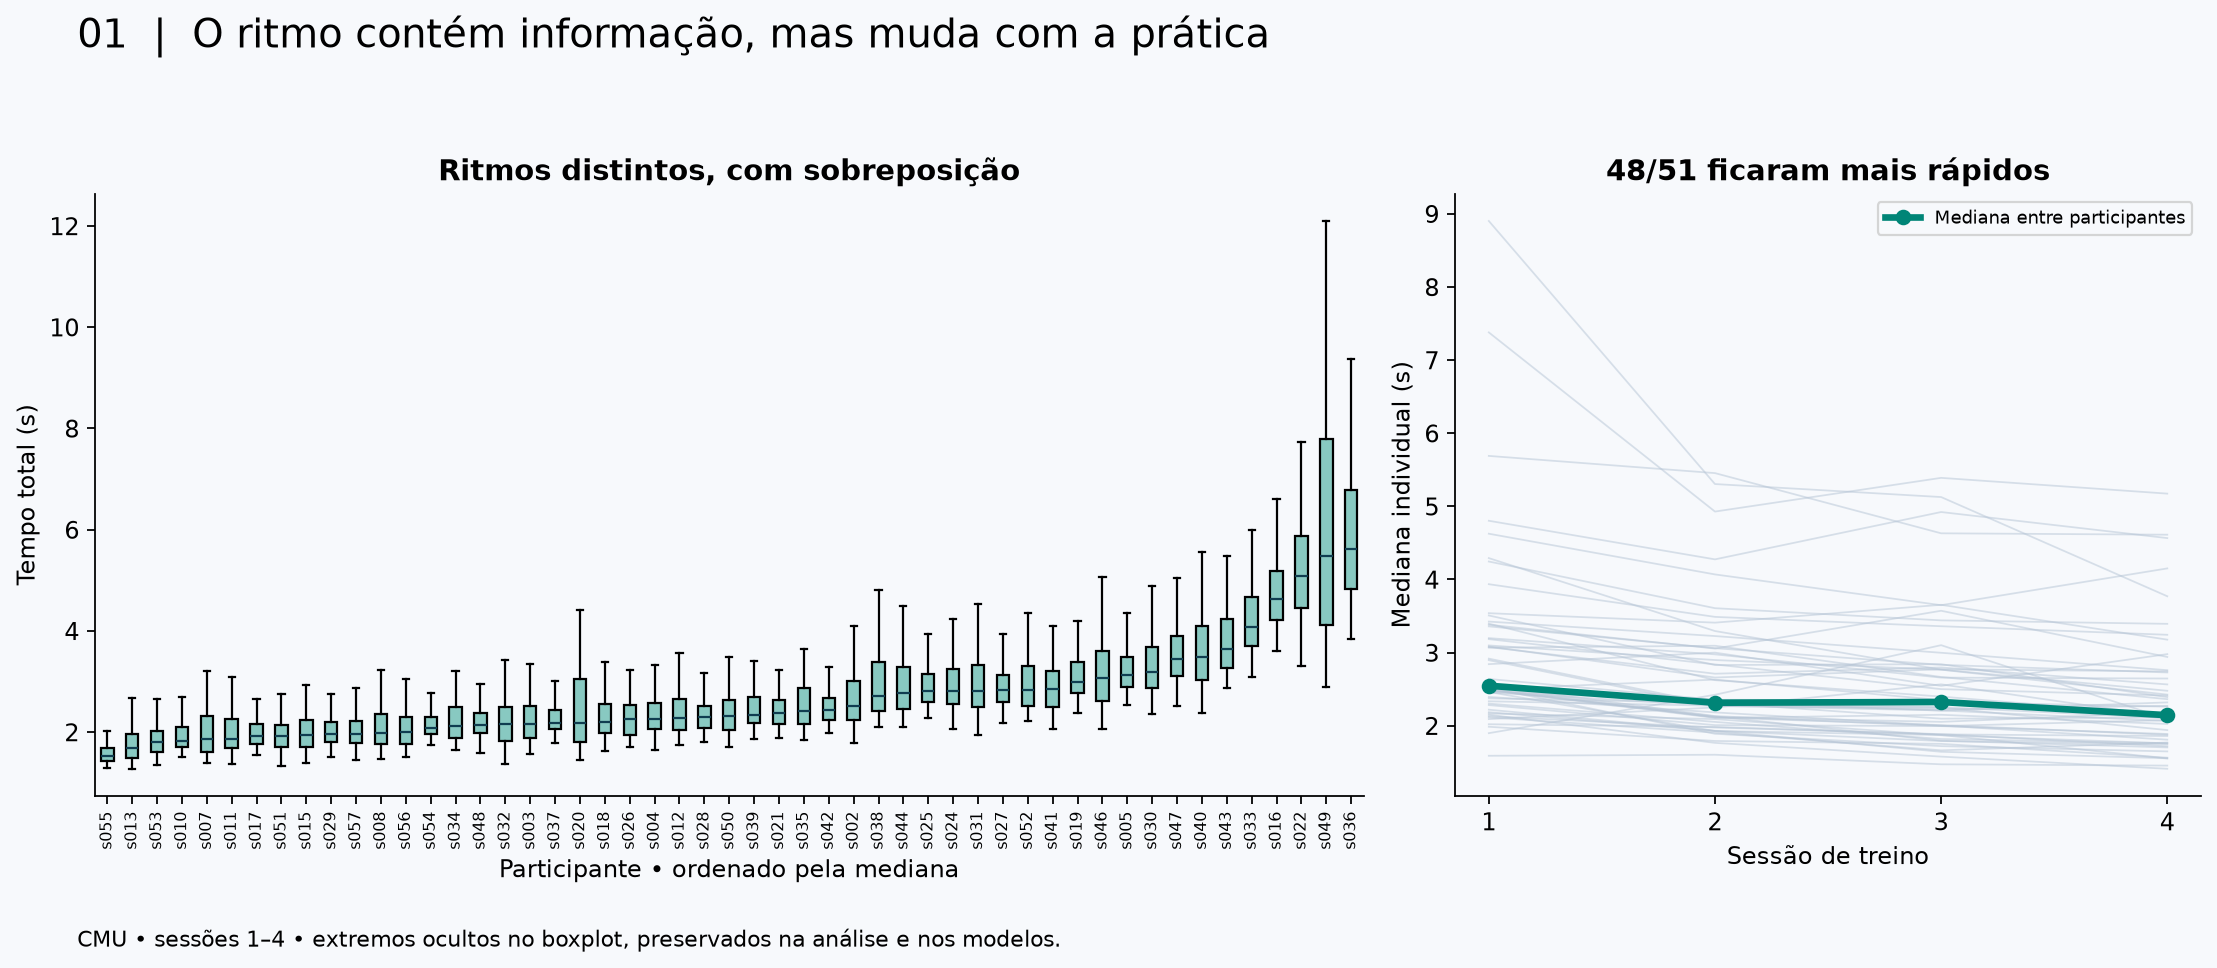

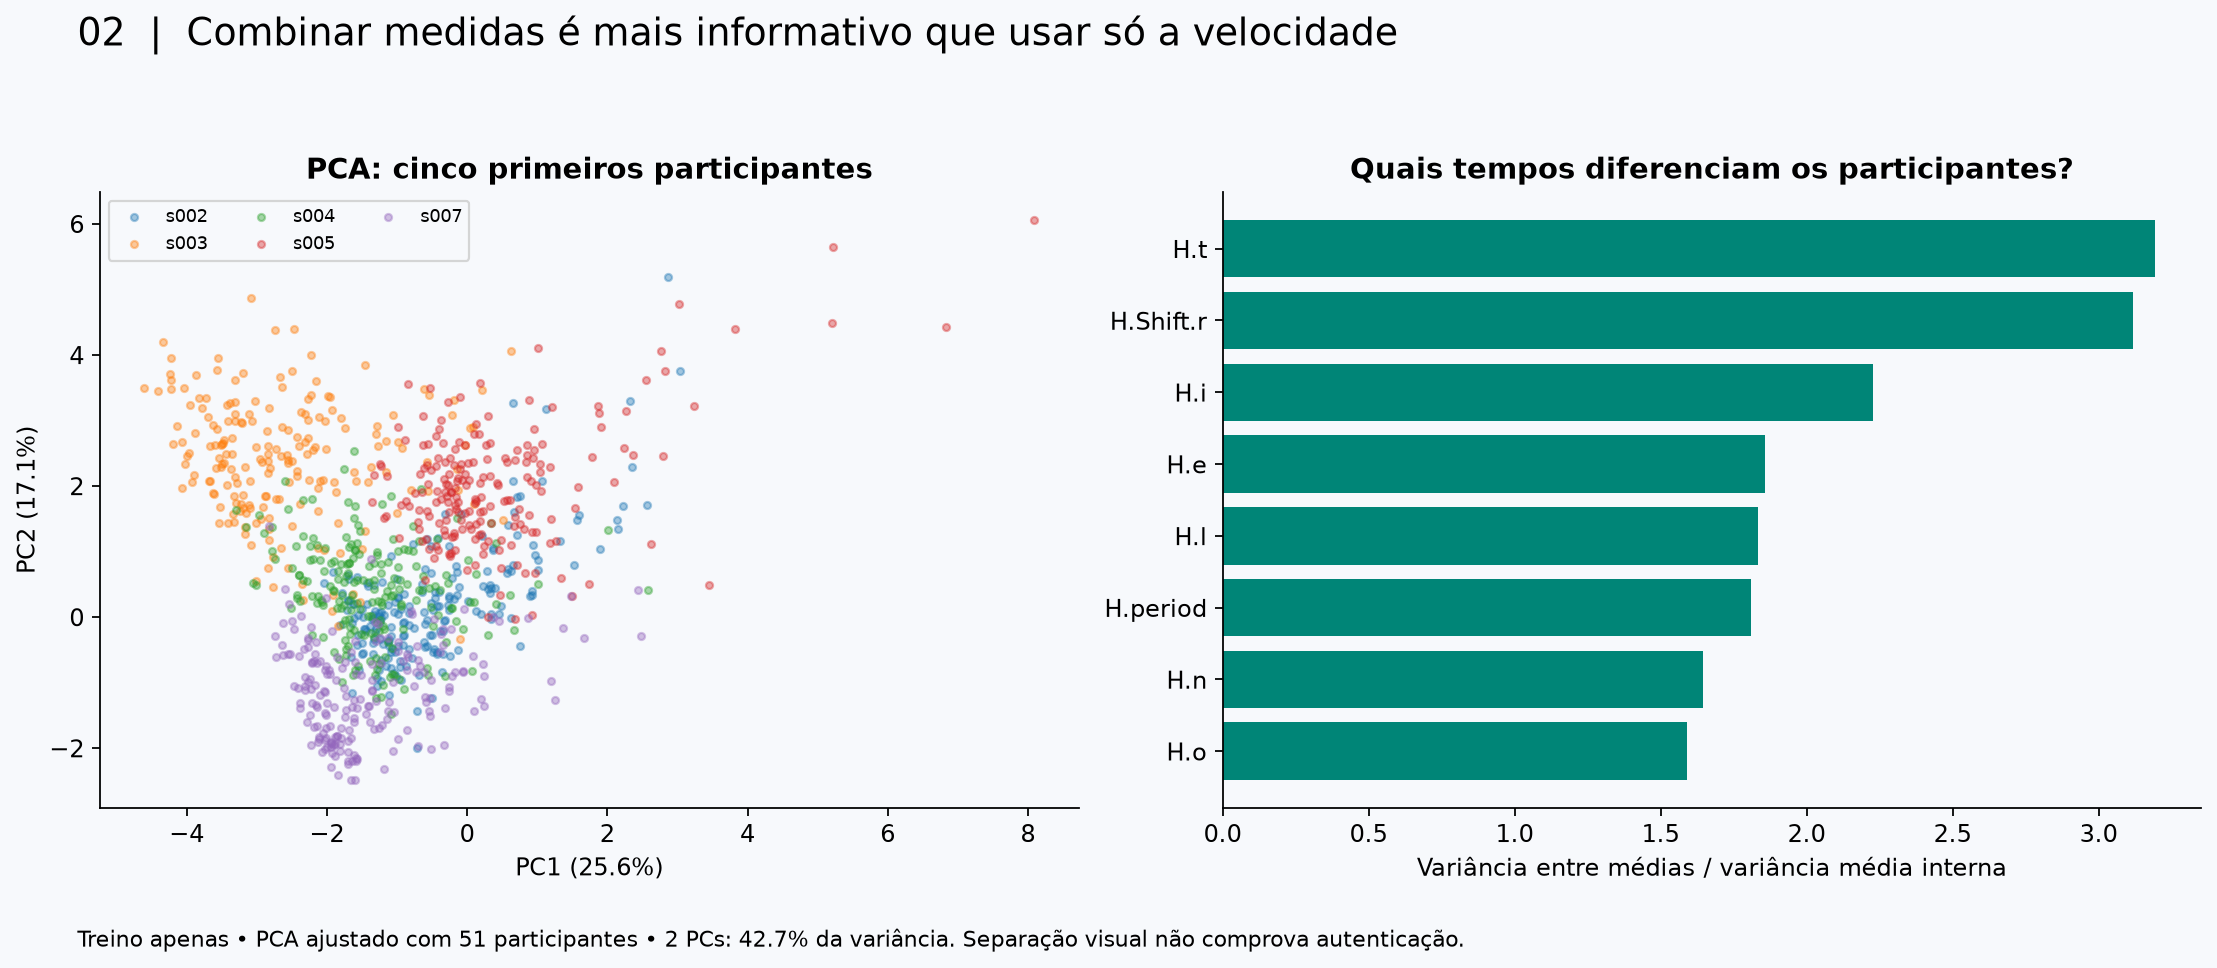

rows                                20400
subjects                               51
features                               31
nulls                                   0
duplicates                              0
train_rows                          10200
validation_rows                      5100
test_rows                            5100
train_median_min                   1.5252
train_median_max                  5.60675
subjects_faster_session4               48
median_change_session1_4_pct   -18.940086
pca_2_variance                   0.427064
pca_95_components                      17
kmeans_ari_training              0.235343
top_feature                           H.t
ud_negative_count                    8503
selected_model                    XGBoost
dtype: object

In [3]:
display(Image(filename=str(ROOT / 'figures' / '01_ritmo_e_sessoes.png')))
display(Image(filename=str(ROOT / 'figures' / '02_pca_e_variaveis.png')))
display(pd.Series(json.loads((ROOT / 'results' / 'eda.json').read_text())))

## Modelagem


### Formulação supervisionada

Construímos **51 classificadores binários por família**, um para cada conta. Classe 1 significa genuíno; classe 0 significa outro participante. As mesmas identidades aparecem em sessões diferentes em treino, validação e teste. Esse desenho mede novas digitações de participantes conhecidos; não mede generalização para novos impostores.

Todos os modelos recebem as 31 medidas originais. `subject`, sessão, repetição e tempo total calculado não entram como preditores. PCA e K-means são diagnósticos exploratórios e não alimentam os classificadores.

### Protocolo temporal e prevenção de vazamento

| Etapa | Sessões | Linhas únicas | Genuínas por conta | Impostoras por conta |
|---|---|---:|---:|---:|
| Treino final | 1–4 | 10.200 | 200 | 10.000 |
| Validação de limiar | 5–6 | 5.100 | 100 | 5.000 |
| Teste final | 7–8 | 5.100 | 100 | 5.000 |

A otimização acontece **dentro das sessões 1–4**, em dois folds progressivos: treinar em 1–2 e avaliar em 3; treinar em 1–3 e avaliar em 4. Cada configuração recebe a média de AUC entre os 51 participantes e os dois folds. A mesma configuração escolhida é aplicada a todas as contas da família. A família selecionada é aquela com maior média nessa validação; não é escolhida pelo teste.

Depois, cada modelo é ajustado em 1–4. O limiar individual é escolhido em 5–6 para minimizar a diferença absoluta entre FAR e FRR; em empate, escolhe-se a menor FAR. A decisão é `score >= limiar`. Não reajustamos o modelo após escolher o limiar. As sessões 7–8 são usadas somente para avaliação final. Nenhuma etapa embaralha linhas entre sessões. A padronização da regressão é ajustada separadamente em cada treino por meio de um pipeline, conforme as [boas práticas do scikit-learn](https://scikit-learn.org/stable/common_pitfalls.html).

Não há sobreposição de registros entre as três etapas; há **sobreposição intencional de identidades**, uma limitação do cenário fechado. A pequena quantidade de sessões também limita a variedade temporal avaliada.

### Modelos e escolhas técnicas

| Família | Justificativa | Configuração |
|---|---|---|
| Sempre rejeitar | Referência ingênua que expõe a fragilidade da acurácia | Score constante; todas as tentativas rejeitadas |
| Regressão logística | Baseline supervisionado linear, regularizado | StandardScaler, C=1, pesos balanceados, máximo de 2.000 iterações |
| Árvore de decisão | Regras não lineares e interações; controle de complexidade | Busca: profundidades 4/8 e mínimos de 5/20 linhas por folha |
| XGBoost | Combinação sequencial de árvores para capturar interações | Busca: profundidades 2/3, 120 árvores; taxa 0,08; peso positivo 50 |

Árvore selecionada: profundidade **4**, mínimo **20** por folha. XGBoost selecionado: profundidade **3**, **120** árvores. `subsample=1`, `colsample_bytree=1`, método `hist`, duas threads e semente 42. A busca é pequena e declarada; não representa otimização exaustiva. Detalhes dos parâmetros estão na [documentação oficial do XGBoost](https://xgboost.readthedocs.io/en/stable/parameter.html).

A ponderação preserva todos os exemplos e dá mais peso à classe rara durante o ajuste. Não usamos oversampling. Os scores de saída não são apresentados como probabilidades calibradas: com pesos de classe e prevalência experimental, um score de 0,9 não significa 90% de certeza operacional.

### Métricas e critério de seleção

- **FAR = FP / (FP + TN):** proporção de impostores aceitos.
- **FRR = FN / (FN + TP):** proporção de genuínos rejeitados.
- **AUC-ROC:** capacidade de ordenar genuínos acima de impostores ao variar o limiar.
- **EER:** interseção aproximada entre FAR e FRR, obtida por interpolação linear da ROC. É uma medida descritiva de separação, não o erro observado no limiar operacional. Com scores discretos, a interseção interpolada pode não ser atingível por um único limiar determinístico.

A implementação usa a orientação de classe positiva da [ROC do scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_curve.html). As métricas são calculadas por conta e depois recebem média simples (**macro**). Todas as contas têm o mesmo número de exemplos. Desvio-padrão e extremos estão nos CSVs; não são intervalos de confiança.

Acurácia não é critério de seleção: sempre rejeitar produz 98,04% de acurácia, mas FRR de 100%. O critério de AUC é útil para esta comparação acadêmica, porém não incorpora os custos de fraude e bloqueio. Um produto real precisaria de uma meta de FAR definida pelo negócio e validação independente do limiar.



In [4]:
RECALCULAR = False  # True executa novamente treino, validação, teste e cinco figuras.
sys.path.insert(0, str(ROOT / 'src'))
if RECALCULAR:
    from analysis import main
    main()
else:
    print('Leitura dos resultados incluídos. Defina RECALCULAR = True para regenerar.')
display(pd.read_csv(ROOT / 'results' / 'cv_summary.csv'))
print((ROOT / 'results' / 'selection.json').read_text())

Leitura dos resultados incluídos. Defina RECALCULAR = True para regenerar.


,model,config,params,AUC
0,Regressão logística,0,{},0.963707
1,XGBoost,0,"{""max_depth"": 2, ""n_estimators"": 120}",0.992543
2,XGBoost,1,"{""max_depth"": 3, ""n_estimators"": 120}",0.993932
3,Árvore de decisão,0,"{""max_depth"": 4, ""min_samples_leaf"": 5}",0.870112
4,Árvore de decisão,1,"{""max_depth"": 4, ""min_samples_leaf"": 20}",0.874559
5,Árvore de decisão,2,"{""max_depth"": 8, ""min_samples_leaf"": 5}",0.838698
6,Árvore de decisão,3,"{""max_depth"": 8, ""min_samples_leaf"": 20}",0.865595


{
  "criterion": "AUC macro nos dois folds temporais",
  "selected_family": "XGBoost",
  "hyperparameters": {
    "Regressão logística": {},
    "Árvore de decisão": {
      "max_depth": 4,
      "min_samples_leaf": 20
    },
    "XGBoost": {
      "max_depth": 3,
      "n_estimators": 120
    }
  }
}


,AUC,EER,FAR,FRR
model,,,,
Regressão logística,0.955854,0.086082,0.085373,0.111569
Sempre rejeitar,0.500000,0.500000,0.000000,1.000000
XGBoost,0.979113,0.053831,0.037494,0.107451
Árvore de decisão,0.858409,0.182108,0.080235,0.223333


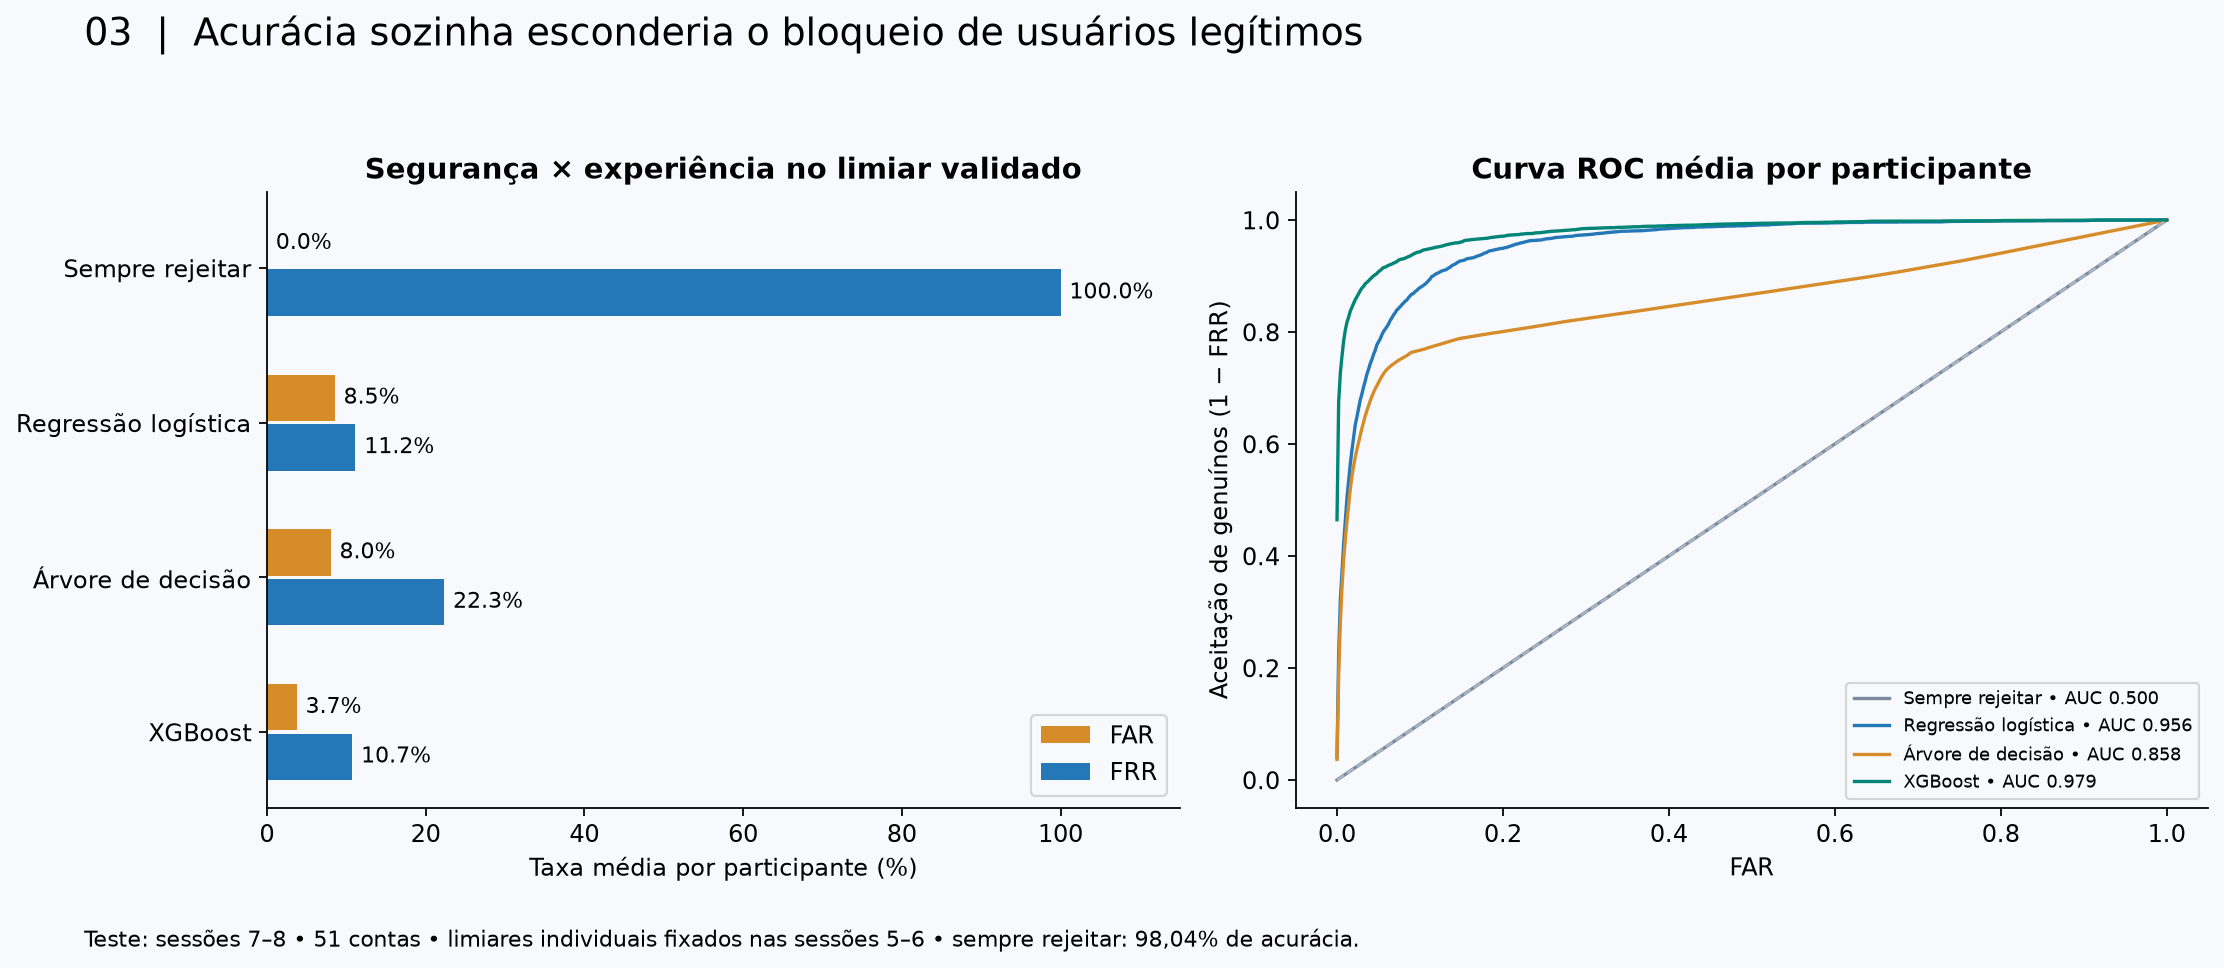

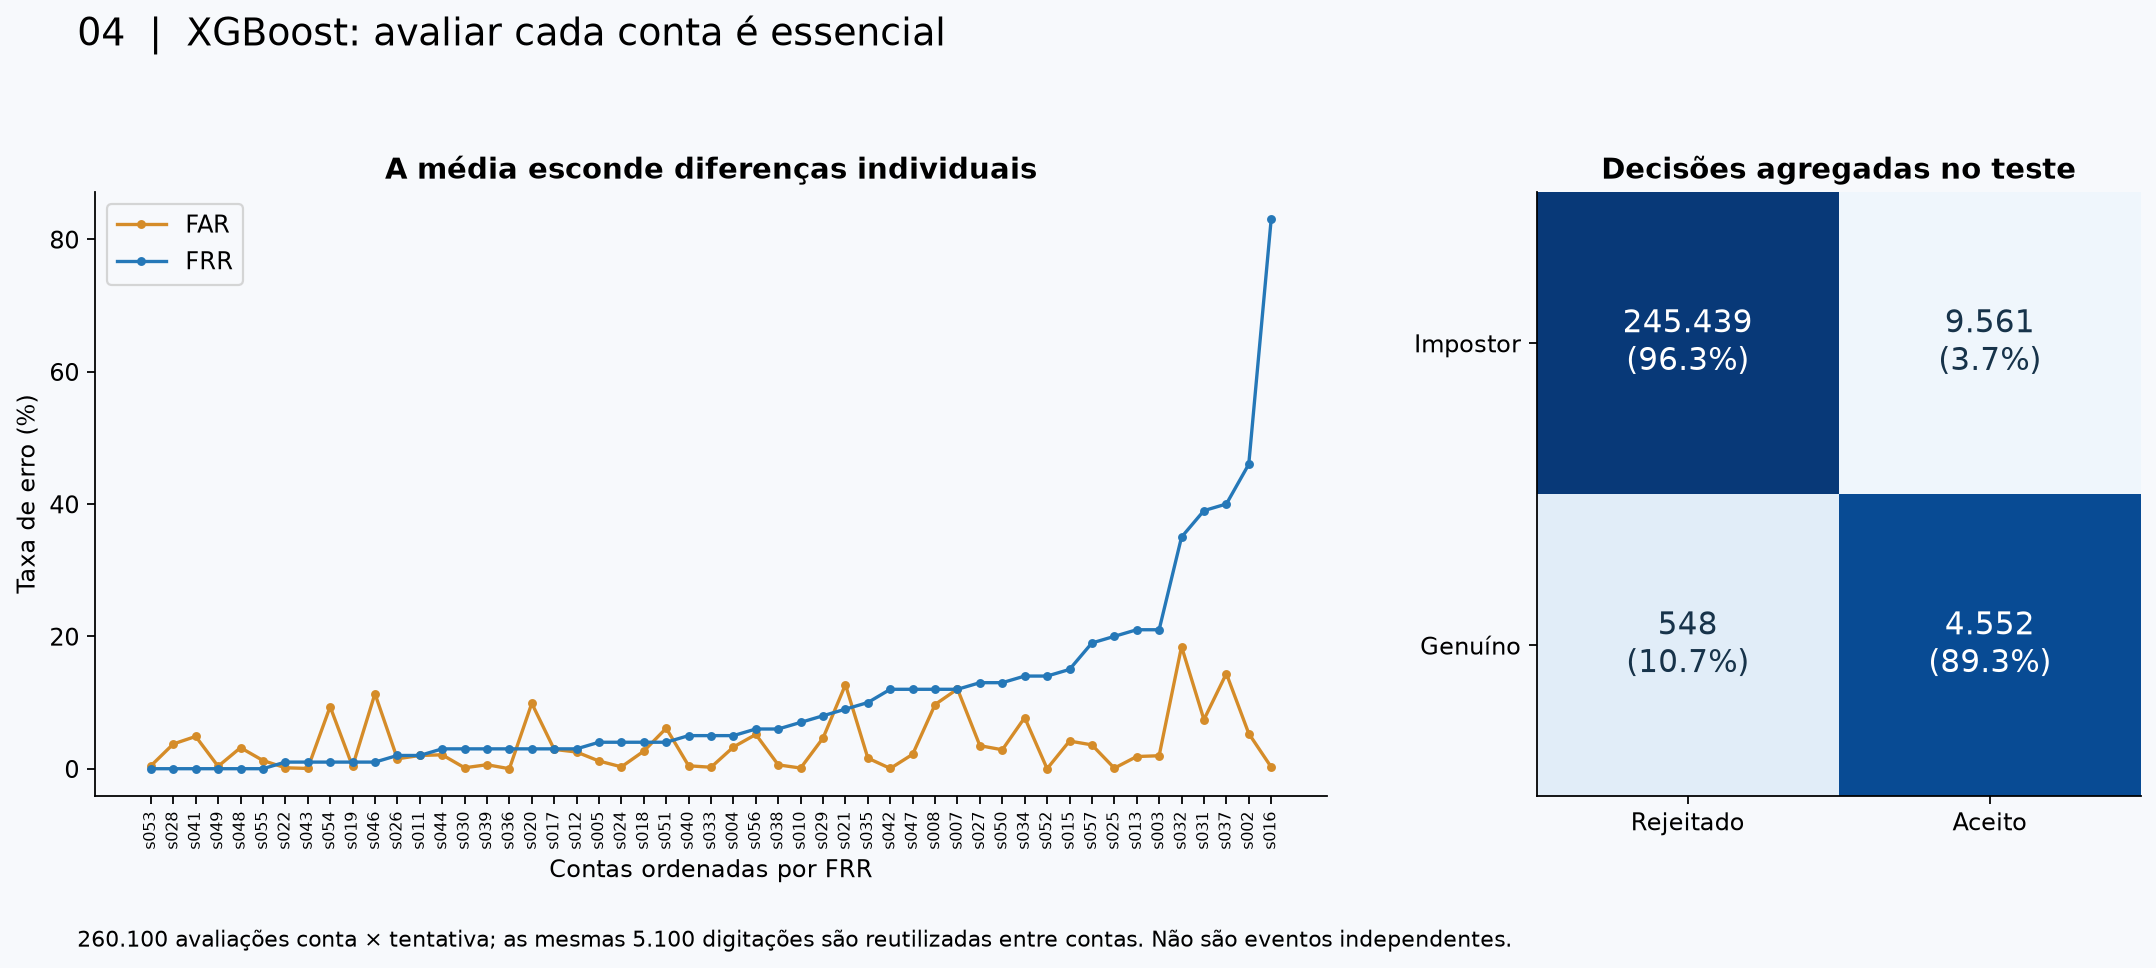

In [5]:
metrics = pd.read_csv(ROOT / 'results' / 'metrics_by_subject.csv', float_precision='round_trip')
summary = metrics.groupby('model')[['AUC', 'EER', 'FAR', 'FRR']].mean()
display(summary.round(6))
display(Image(filename=str(ROOT / 'figures' / '03_comparacao_modelos.png')))
display(Image(filename=str(ROOT / 'figures' / '04_erros_por_conta.png')))

### Auditoria independente das previsões
A seguir, reconstruímos as taxas diretamente dos pares conta × tentativa salvos. Eles são dependentes, porque reutilizam digitações contra várias contas.

In [6]:
from sklearn.metrics import confusion_matrix, roc_auc_score
pred = pd.read_csv(ROOT / 'results' / 'predictions.csv.gz', float_precision='round_trip')
assert len(pred) == 4 * 51 * 5100
checks = []
for (family, account), g in pred.groupby(['model', 'account']):
    tn, fp, fn, tp = confusion_matrix(g.actual, g.score >= g.threshold, labels=[0, 1]).ravel()
    original = metrics[(metrics.model == family) & (metrics.subject == account)].iloc[0]
    assert (tn, fp, fn, tp) == (original.TN, original.FP, original.FN, original.TP)
    assert abs(roc_auc_score(g.actual, g.score) - original.AUC) < 1e-10
    checks.append((family, account))
print(f'{len(checks)} combinações de modelo e conta verificadas com as previsões salvas.')

204 combinações de modelo e conta verificadas com as previsões salvas.


## Conclusões


### Resposta ao problema

Há informação útil no ritmo de digitação para distinguir participantes neste cenário. Entre as configurações comparadas, o XGBoost selecionado pela validação alcançou AUC média **0,9791** e EER média **5,38%**. No limiar escolhido antes do teste, aceitou **3,75%** das tentativas de outros participantes e bloqueou **10,75%** das tentativas genuínas.

A recomendação é seguir com pesquisa e validação de uma camada complementar de autenticação, mantendo uma alternativa de verificação para o usuário. **O experimento não justifica implantação autônoma em produção.** A aceitação de impostores e o bloqueio de genuínos continuam relevantes, e os erros variam substancialmente entre contas.

### Limitações

1. **Cenário fechado:** negativos de teste pertencem a pessoas que já forneciam negativos no treino. Futuros experimentos devem separar identidades impostoras entre treino e teste.
2. **Domínio restrito:** uma senha fixa, teclado físico e ambiente controlado. Não há evidência direta para telas de celular, senhas variadas, dispositivos diferentes ou digitação livre.
3. **Ataques não simulados:** outras pessoas digitando a senha não reproduzem necessariamente um ataque dirigido, imitação ou injeção de eventos.
4. **Amostra e repetição:** 51 participantes não representam a população geral; sessões e avaliações entre contas são dependentes. Não fizemos inferência populacional ou testes formais de superioridade.
5. **Escolha de limiar:** equilibrar erros na validação não garante FAR/FRR iguais no futuro, nem atende uma exigência de segurança definida por negócio.
6. **Comparação externa:** nosso protocolo supervisionado, negativos e partições diferem do experimento original da CMU. Seus resultados publicados não são diretamente comparáveis aos nossos.
7. **Privacidade:** um eventual produto requer avaliação própria da coleta, finalidade, retenção, controle de acesso e proteção dos perfis comportamentais. Este relatório não estabelece uma base jurídica para uso comercial.

### Próximos passos

Definir o custo de cada erro e uma meta de FAR; testar impostores não vistos; ampliar o número de sessões e dispositivos; avaliar mudança de comportamento; analisar estabilidade dos limiares e probabilidades calibradas; comparar um detector treinado apenas com o genuíno; e usar desenho de validação que respeite a dependência entre sessões e pessoas.



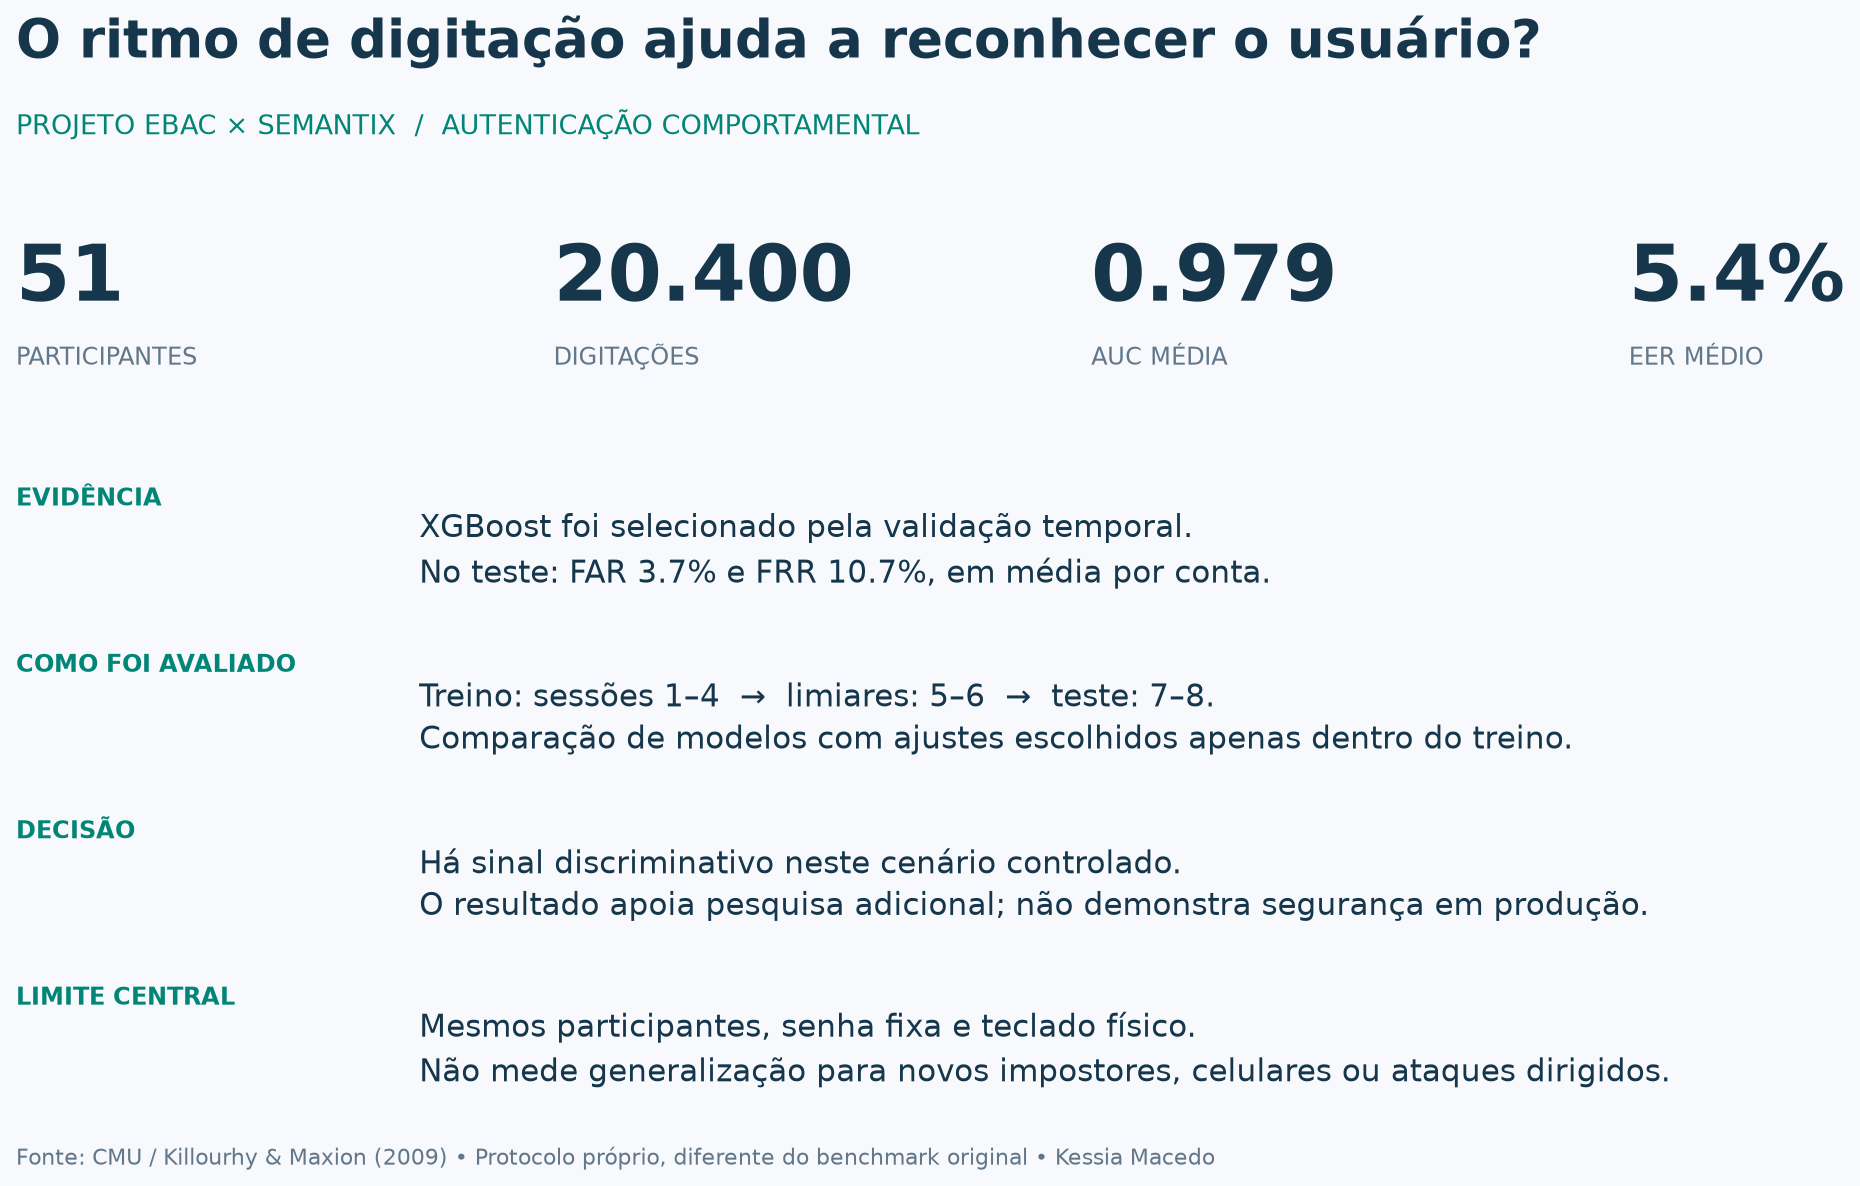

{
  "seed": 42,
  "data_md5": "470235f96568f28f9ea0da62234ec857",
  "data_sha256": "b11d23538b1865fa6ecf4e8b78567caa312e9c1027604bb022fcc6ad7eaa7a33",
  "python": "3.14.6",
  "versions": {
    "pandas": "3.0.3",
    "numpy": "2.4.6",
    "scikit-learn": "1.9.0",
    "matplotlib": "3.11.0",
    "xgboost": "3.4.1"
  },
  "elapsed_seconds": 50.72,
  "protocol": "train 1–4; threshold 5–6; test 7–8",
  "cv": "train 1–2 / validate 3; train 1–3 / validate 4"
}


In [7]:
display(Image(filename=str(ROOT / 'figures' / '05_resumo_executivo.png')))
print((ROOT / 'results' / 'run_manifest.json').read_text())

### Referências e estado
[CMU — Killourhy & Maxion (2009)](https://www.cs.cmu.edu/~keystroke/). Consulte `docs/RELATORIO.md` para referências metodológicas, limitações e documentação.

Entrega local concluída. GitHub e envio à plataforma pendentes por escolha da autora.